In [22]:
import numpy as np
import jax
import jax.numpy as jnp
from flax import nnx

import ai_surrogate_models as ai
from scattering_simulation import prepare_lens_scattering_solver
import topology_parametrization
import field_postprocessing
from manufacturing_constraints import too_thin_area
from manufacturing_constraints import detect_too_thin_solid, detect_too_thin_void

import optax
from mutax import differential_evolution

from field_plotter import visible_amplitude_colormap
import matplotlib.pyplot as plt

In [2]:
jax.config.update("jax_default_matmul_precision", "float32")
print(jax.devices())

[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3), CpuDevice(id=4), CpuDevice(id=5), CpuDevice(id=6), CpuDevice(id=7)]


## Lens geometry and constraints

In [4]:
period = 2000
p_red = period / 650
p_green = period / 550
p_blue = period / 450
focal_distance = 3500

In [5]:
n_px = 100
topology = topology_parametrization.GaussianField(n_px, sigma=16, symmetry_type='main_diagonal')

In [6]:
n_px_constraints = 200
min_width = 150
min_width_px = round(min_width * n_px_constraints / period)
min_width_px = (min_width_px // 2) * 2 + 1
print('Min width in pixels:', min_width_px, 'which corresponds to', min_width_px * period / n_px_constraints, 'nm')

Min width in pixels: 15 which corresponds to 150.0 nm


## Load FNO models

In [7]:
common_fno_kwargs = {'model_type': ai.ScatteringFNO, 'dout': 4, 'hidden_dims': [64] * 7, 'modes': 16, 'activation': nnx.gelu}
red_model = ai.load_model('ai_models/fno_red_freeform.msgpack', **common_fno_kwargs)
green_model = ai.load_model('ai_models/fno_green_freeform.msgpack', **common_fno_kwargs)
blue_model = ai.load_model('ai_models/fno_blue_freeform.msgpack', **common_fno_kwargs)

## Prepare rigorous simulation functions

In [8]:
common_sim_kwargs = {'period': 2000, 'lens_thickness': 600, 'substrate_thickness': 500,
                     'approximate_number_of_terms': 600, 'propagate_by_distance': 0}
red_sim, red_basis = prepare_lens_scattering_solver(wavelength=650, **common_sim_kwargs)
green_sim, green_basis = prepare_lens_scattering_solver(wavelength=550, **common_sim_kwargs)
blue_sim, blue_basis = prepare_lens_scattering_solver(wavelength=450, **common_sim_kwargs)

print(red_basis.shape, green_basis.shape, blue_basis.shape)

(2, 29) (2, 45) (2, 61)


## Efficiency and objective

In [9]:
def params_to_normalized_amps_xy_rgb(params, sim_func_red, sim_func_green, sim_func_blue):
    amps_red = sim_func_red(params).squeeze()[:red_basis.shape[1]].T
    amps_green = sim_func_green(params).squeeze()[:green_basis.shape[1]].T
    amps_blue = sim_func_blue(params).squeeze()[:blue_basis.shape[1]].T

    amps_red = field_postprocessing.normalize_power(amps_red, p_red, red_basis)[:2]
    amps_green = field_postprocessing.normalize_power(amps_green, p_green, green_basis)[:2]
    amps_blue = field_postprocessing.normalize_power(amps_blue, p_blue, blue_basis)[:2]

    amps_red = field_postprocessing.propagate_amps_in_free_space(amps_red, focal_distance, red_basis, 650, period)
    amps_green = field_postprocessing.propagate_amps_in_free_space(amps_green, focal_distance, green_basis, 550, period)
    amps_blue = field_postprocessing.propagate_amps_in_free_space(amps_blue, focal_distance, blue_basis, 450, period)

    return amps_red, amps_green, amps_blue

def params_to_focused_powers(params, true_sim=True):
    if true_sim:
        sim_funcs = (
            lambda x: red_sim(topology(x)),
            lambda x: green_sim(topology(x)),
            lambda x: blue_sim(topology(x))
        )
    else:
        sim_funcs = (
            lambda x: field_postprocessing.extract_amps_from_fields(red_model(topology(x)[None])[0], red_basis),
            lambda x: field_postprocessing.extract_amps_from_fields(green_model(topology(x)[None])[0], green_basis),
            lambda x: field_postprocessing.extract_amps_from_fields(blue_model(topology(x)[None])[0], blue_basis)
        )

    amps_red, amps_green, amps_blue = params_to_normalized_amps_xy_rgb(params, *sim_funcs)

    red_power = field_postprocessing.calculate_focused_power(amps_red, p_red, red_basis, relative_focal_point=(0.25, 0.25))
    green_power = (
        field_postprocessing.calculate_focused_power(amps_green, p_green, green_basis, relative_focal_point=(0.25, 0.75))
        + field_postprocessing.calculate_focused_power(amps_green, p_green, green_basis, relative_focal_point=(0.75, 0.25))
    )
    blue_power = field_postprocessing.calculate_focused_power(amps_blue, p_blue, blue_basis, relative_focal_point=(0.75, 0.75))

    return jnp.array([red_power, green_power, blue_power])

In [10]:
def objective(x, true_sim, penalty_coeff):
    eff = jnp.mean(params_to_focused_powers(x, true_sim=true_sim))
    invalid = too_thin_area(topology(x, n_px_constraints), min_width_px)
    return eff - (jnp.exp(penalty_coeff * invalid) - 1)

## Random restart gragient descent FNO-based optimization

In [14]:
loss_value_and_grad_ai = jax.value_and_grad(lambda x, pc: objective(x, true_sim=False, penalty_coeff=pc), argnums=0)
optimizer = optax.adam(learning_rate=1e-2)

n_restarts = 2
n_steps = 500

penalty_transition_steps = int(n_steps * 0.8)
penalty_coeff_schedule = optax.schedules.linear_schedule(
    init_value=1, end_value=100, transition_steps=penalty_transition_steps)

overall_best_x = None
overall_max_f = -1e10
max_f_history = []
best_x_history = []

@jax.jit
def ai_step(x, opt_state, penalty_coeff):
    obj_f, grad = loss_value_and_grad_ai(x, penalty_coeff)
    updates, opt_state = optimizer.update(-grad, opt_state)
    x = optax.apply_updates(x, updates)
    x = jnp.clip(x, topology.minval, topology.maxval)
    return x, opt_state, obj_f

for rng_seed in range(n_restarts):
    x_init = jax.random.uniform(
        jax.random.key(rng_seed),
        shape=topology.n_geometrical_parameters,
        minval=topology.minval,
        maxval=topology.maxval
    )
    opt_state = optimizer.init(x_init)

    x = x_init
    max_f = -1e10
    best_x = None

    for i in range(n_steps):
        new_x, opt_state, obj_f = ai_step(x, opt_state, penalty_coeff_schedule(i))
        if i >= penalty_transition_steps and obj_f > max_f:
            max_f = obj_f
            best_x = x
        x = new_x
        print(i, obj_f, sep='\t')

    if max_f > overall_max_f:
        overall_max_f = max_f
        overall_best_x = best_x
    max_f_history.append(max_f)
    best_x_history.append(best_x)
    print(rng_seed, max_f, overall_max_f)

0	-0.20990601
1	-0.22340634
2	-0.21595915
3	-0.21275099
4	-0.1267371
5	-0.070626564
6	-0.058870144
7	-0.016295739
8	0.011606467
9	0.06995842
0 0.06995842 0.06995842
0	-0.28029588
1	-0.2184619
2	-0.16990677
3	-0.12717424
4	-0.08790059
5	-0.07698403
6	-0.058881827
7	-0.04442909
8	-0.027401872
9	0.055171702
1 0.055171702 0.06995842


Objective: 0.06995842
Invalid area: 0.14892207


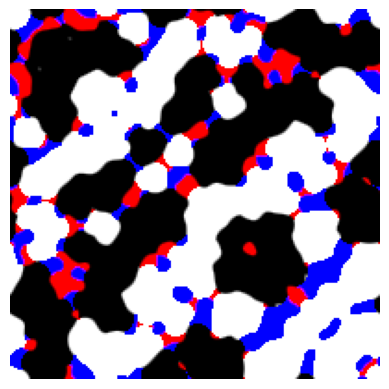

In [57]:
x_to_inspect = best_x_history[0]
print('Objective:', max_f_history[0])
print('Invalid area:', too_thin_area(topology(x_to_inspect, n_px_constraints), min_width_px))

pattern = topology(x_to_inspect, n_px_constraints)
invalid_solid = detect_too_thin_solid(pattern, min_width_px)
invalid_void = detect_too_thin_void(pattern, min_width_px)

r = pattern * np.logical_not(np.logical_and(invalid_solid == 0, invalid_void > 0))
g = pattern * np.logical_and(invalid_solid == 0, invalid_void == 0)
b = pattern * np.logical_and(invalid_solid == 0, invalid_void == 0) + (invalid_void > 0)

plt.imshow(np.stack([r, g, b], axis=-1))
plt.axis('off')
plt.show()

# Choose TOP candidates and compare FNO vs FMM for them

In [58]:
n_top = 10
top_indices = np.flip(np.argsort(max_f_history))[:n_top]

In [ ]:
for rng_seed in top_indices:
    x = jax.random.uniform(
        jax.random.key(rng_seed),
        shape=topology.n_geometrical_parameters,
        minval=topology.minval,
        maxval=topology.maxval
    )
    opt_state = optimizer.init(x_init)

    for i in range(n_steps):
        pc = penalty_coeff_schedule(i)
        obj_f_true = objective(x, true_sim=True, penalty_coeff=pc)
        x, opt_state, obj_f = ai_step(x, opt_state, pc)
        print(rng_seed, i, obj_f, obj_f_true, sep='\t')

# Rigorous Refinement

In [ ]:
loss_value_and_grad_true = jax.value_and_grad(lambda x, pc: objective(x, true_sim=True, penalty_coeff=pc), argnums=0)
refinment_optimizer = optax.adam(learning_rate=1e-2)

n_refinment_steps = 200

penalty_transition_refinment_steps = int(n_refinment_steps * 0.8)
penalty_coeff_refinment_schedule = optax.schedules.linear_schedule(
    init_value=50, end_value=100, transition_steps=penalty_transition_steps)
# TODO: play with penalty schedule here

refined_top_objectives = []
refined_top_xs = []

@jax.jit
def true_step(x, opt_state, penalty_coeff):
    obj_f, grad = loss_value_and_grad_true(x, penalty_coeff)
    updates, opt_state = refinment_optimizer.update(-grad, opt_state)
    x = optax.apply_updates(x, updates)
    x = jnp.clip(x, topology.minval, topology.maxval)
    return x, opt_state, obj_f

for rng_seed in top_indices:
    x = best_x_history[rng_seed]
    opt_state = optimizer.init(x)

    max_f = -1e10
    best_x = None

    for i in range(n_refinment_steps):
        new_x, opt_state, obj_f = true_step(x, opt_state, penalty_coeff_schedule(i))
        if i >= penalty_transition_refinment_steps and obj_f > max_f:
            max_f = obj_f
            best_x = x
        x = new_x
        print(rng_seed, i, obj_f, sep='\t')

    refined_top_objectives.append(max_f)
    refined_top_xs.append(best_x)

In [ ]:
np.save(f'refined_top{n_top}_params.npy', np.stack(refined_top_xs, axis=0))